# Part 0 : Setup & Imports

This notebook accompanies the written report for the Applied Investments portfolio strategy project (Prof. Amit Goyal, HEC Lausanne, Fall 2026) and documents every step needed to reproduce the results. The research question is: **"Can a momentum strategy we design keep the momentum premium, reduce its crashes, and still earn alpha after costs, out of sample?"**

Momentum (buy the past 12-month winners, sell the losers) is one of the most robust anomalies in the literature, and one of the few that the Fama-French five-factor model cannot explain. It suffers from two problems that make it hard to defend in front of an investment committee: violent, sudden crashes (spring 2009) and high turnover that erodes the premium after trading costs. Our strategy keeps the premium while addressing both, and is built as a cascade so the contribution of each step can be measured separately.

We test three hypotheses, each tied to a row of the cascade table:

- **H1 (signal)** : the momentum window selected on 1963–2011 does at least as well as the standard 12-1 after 2012.
- **H2 (our rule)** : scaling down the short leg in bear markets with high loser volatility reduces maximum drawdown and the worst month without lowering the Sharpe ratio, and the gain is not explained by time-varying market exposure.
- **H3 (implementation)** : after the turnover buffer and transaction costs, the final strategy has a positive alpha against FF5 + UMD.

All design choices are fixed on the in-sample period (1963–2011). The period 2012–2025 is used only as an out-of-sample test, and no parameter changes after it has been looked at.

Course rules that shape the design: US equity data only, a strategy evaluated with alphas against standard asset pricing models, a report of at most 20 pages (excluding tables, graphs and references), and a 20-minute presentation to the investment committee of our asset management firm.

> **Committee message** : "The momentum premium, without its crashes, implementable after costs, and tested on data we never used to design it."

## 0.1 : Global Conventions

Definitions agreed on by the group before any code is run, so the report, the slides and the code all use the same constants:

- Rebalancing: monthly, on the last trading day of month $t$ (return-based signals change often, so monthly rebalancing is the natural choice). Holding period returns start at $t+1$.
- Value weights: the return of month $t+1$ is weighted by market capitalisation at the end of month $t$.
- Risk-free rate: one-month T-bill from the Kenneth French Data Library.
- Annualisation: mean × 12, volatility × $\sqrt{12}$ for monthly series; × 252 / $\sqrt{252}$ for daily series.
- Sample: holding months from July 1963 (start of FF5) to December 2025 (end of CRSP); in-sample until December 2011, out-of-sample from January 2012. Strategy returns are dated by their holding month.
- Missing data stay missing and are never filled with zero, with one exception: a stock held in a portfolio whose next-month return is missing (no next row and no delisting return) is assumed to earn 0%, rather than being dropped with hindsight. This affects 78 stock-months (0.01%).
- Delisting returns: included in the month of delisting.
- Units: all returns are stored as decimals (0.05 = 5%). Kenneth French and q5 files are in percent and are divided by 100 when loaded.
- Transaction costs: final model to be decided by the group (see `data_notes.txt`, no stock-level spread data available). Fixed 10 / 25 / 50 bp are reported in every case.
- All strategy parameters below are fixed a priori (v2) and are not changed after looking at results.

In [12]:
# Core stack
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

# Display settings
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["axes.grid"] = True

# Folders: relative paths, so the notebook runs on every group member's computer
# (open the notebook from the repo root, where data/ sits next to it)
DATA = Path("data")
PROCESSED = DATA / "processed"   # fast Parquet copies, created in Part 1 (ignored by Git)
OUTPUT = Path("output")          # figures and tables for the report
OUTPUT.mkdir(exist_ok=True)

# Sample dates
DATA_START   = pd.Timestamp("1959-01-31")  # first month in the CRSP file (history for the signals)
SAMPLE_START = pd.Timestamp("1963-07-31")  # first holding month (start of FF5)
IS_END       = pd.Timestamp("2011-12-31")  # last in-sample month
OOS_START    = pd.Timestamp("2012-01-31")  # first out-of-sample month
SAMPLE_END   = pd.Timestamp("2025-12-31")  # last month in CRSP

# Universe (Part 1.5)
MIN_PRICE      = 5.0    # dollars, at formation
SIZE_PCTL      = 20     # exclude stocks below the 20th NYSE market-cap percentile
MIN_OBS_SIGNAL = 8      # minimum monthly returns in the formation window
COMMON_STOCK   = {"SecurityType": "EQTY", "SecuritySubType": "COM", "ShareType": "NS", "USIncFlg": "Y"}
EXCHANGES      = ["N", "A", "Q"]  # NYSE, AMEX, NASDAQ

# Strategy parameters, fixed a priori (v2), never optimised
N_PORT         = 10     # deciles, NYSE breakpoints
RESID_WINDOW   = 36     # months for the FF3 regression (residual momentum)
RESID_MIN_OBS  = 24
BEAR_WINDOW    = 24     # months, cumulative excess market return (bear indicator)
DELTA          = 0.5    # short-leg reduction when the rule triggers
BUFFER_LONG    = 9      # stay long while in deciles 9-10 (enter at 10)
BUFFER_SHORT   = 2      # stay short while in deciles 1-2 (enter at 1)
MM_LEV_CAP     = 2.0    # Moreira-Muir leverage cap
SELECT_MARGIN  = 0.05   # keep 12-1 unless another signal beats it by more than this Sharpe

# Evaluation
COST_SCENARIOS_BP = [10, 25, 50]
NW_LAGS     = 6
T_THRESHOLD = 3.0       # Harvey, Liu & Zhu (2016)
N_SIM       = 1000      # placebo / bootstrap replications
BLOCK_SIZE  = 12        # months, block bootstrap
SEED        = 42
rng = np.random.default_rng(SEED)

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.0 | numpy 2.5.4


## 0.2 : Data Folder Check

Git does not carry the data, so each group member places the 14 files in `data/` (see `README.md`). This cell stops immediately with a clear message if a file is missing or misnamed, instead of failing later with a confusing error. To check that a copy is identical to the reference, run `bash check_data.sh > my_check.txt` and compare it with `check_output_oli.txt`.

In [13]:
REQUIRED_FILES = [
    "Monthly.csv",
    "1959.12.31_1964.12.31.csv",
    "1965.01.01_1980.01.01.csv",
    "1980.01.02_1995.01.02.csv",
    "1995.01.03_2010.01.03.csv",
    "2010.01.04_2025.12.31.csv",
    "F-F_Research_Data_Factors.csv",
    "F-F_Research_Data_5_Factors_2x3.csv",
    "F-F_Momentum_Factor.csv",
    "ME_Breakpoints.csv",
    "Prior_2-12_Breakpoints.csv",
    "10_Portfolios_Prior_12_2.csv",
    "q5_factors_monthly_2025.csv",
    "USREC.csv",
]
DAILY_FILES = REQUIRED_FILES[1:6]

if not DATA.exists():
    raise FileNotFoundError(
        "No data/ folder found. Open the notebook from the repo root and put the 14 CSVs in data/ (see README.md)."
    )

missing = [f for f in REQUIRED_FILES if not (DATA / f).exists()]
if missing:
    raise FileNotFoundError("Missing in data/: " + ", ".join(missing))

file_sizes = pd.Series({f: (DATA / f).stat().st_size / 1e6 for f in REQUIRED_FILES}, name="Size (MB)")
print(f"All {len(REQUIRED_FILES)} data files found ({file_sizes.sum() / 1e3:.1f} GB in total).")
file_sizes.round(1).to_frame()

All 14 data files found (6.1 GB in total).


,Size (MB)
Monthly.csv,459.2000
1959.12.31_1964.12.31.csv,109.2000
1965.01.01_1980.01.01.csv,757.2000
1980.01.02_1995.01.02.csv,1359.9000
1995.01.03_2010.01.03.csv,1613.9000
2010.01.04_2025.12.31.csv,1761.0000
F-F_Research_Data_Factors.csv,0.1000
F-F_Research_Data_5_Factors_2x3.csv,0.1000
F-F_Momentum_Factor.csv,0.0000
ME_Breakpoints.csv,0.3000


---
# Part 1 : Data Loading & Cleaning

## 1.1 : Load the Stock-Level Database

We use US stock data from CRSP via WRDS, in the new CIZ format. Following lecture 1, the sample includes all stocks, alive and dead, and is as long as possible: January 1959 to December 2025, covering the oil crisis, the internet bubble, the global financial crisis and COVID.

**Monthly file** (`Monthly.csv`, 4.96 million rows, 40,056 stocks): `PERMNO`, `MthCalDt`, `MthRet` (total return, delisting returns already included), `MthRetx`, `MthPrc`, `ShrOut` (in thousands), `MthVol`, `PrimaryExch`, `SecurityType`, `SecuritySubType`, `ShareType`, `USIncFlg`, `Ticker`, `PERMCO`, `HdrCUSIP`.

**Daily files** (5 files, 31 Dec 1959 to 31 Dec 2025, about 102 million rows): `PERMNO`, `DlyCalDt`, `DlyPrc`, `DlyRet`, `Ticker`, `PERMCO`, `HdrCUSIP`.

No bid/ask quotes or daily low/high prices are available, so stock-level spreads cannot be measured. The consequences for the cost model are discussed in `data_notes.txt` and Part 4.

This is the main data source for the whole notebook.

In [14]:
# Load the CRSP monthly file: only the columns we need, with compact types.
# The first run reads the 460 MB CSV (about 1 min) and saves a Parquet copy;
# later runs load the Parquet copy in a few seconds.
PROCESSED.mkdir(parents=True, exist_ok=True)
MONTHLY_PQ = PROCESSED / "crsp_monthly_raw.parquet"

MONTHLY_COLS = ["PERMNO", "MthCalDt", "MthRet", "MthPrc", "ShrOut", "MthVol",
                "PrimaryExch", "SecurityType", "SecuritySubType", "ShareType", "USIncFlg", "Ticker"]
MONTHLY_TYPES = {"PERMNO": "int32", "MthRet": "float64", "MthPrc": "float64",
                 "ShrOut": "float64", "MthVol": "float64",
                 "PrimaryExch": "category", "SecurityType": "category", "SecuritySubType": "category",
                 "ShareType": "category", "USIncFlg": "category", "Ticker": "string"}

if MONTHLY_PQ.exists():
    crsp_m = pd.read_parquet(MONTHLY_PQ)
    print("Loaded from Parquet cache.")
else:
    crsp_m = pd.read_csv(DATA / "Monthly.csv", usecols=MONTHLY_COLS, dtype=MONTHLY_TYPES,
                         parse_dates=["MthCalDt"])
    crsp_m.to_parquet(MONTHLY_PQ, index=False)
    print("Read from CSV and saved a Parquet copy for next time.")

print(f"{len(crsp_m):,} rows, {crsp_m['PERMNO'].nunique():,} stocks, "
      f"{crsp_m.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
crsp_m.head()

Loaded from Parquet cache.
4,961,319 rows, 40,056 stocks, 300 MB in memory


,PERMNO,PrimaryExch,USIncFlg,SecurityType,SecuritySubType,ShareType,Ticker,MthCalDt,MthPrc,MthRet,MthVol,ShrOut
0,10000,Q,Y,EQTY,COM,NS,OMFGA,1986-01-31,4.3750,0.7073,177082.0000,3680.0000
1,10000,Q,Y,EQTY,COM,NS,OMFGA,1986-02-28,3.2500,-0.2571,82800.0000,3680.0000
2,10000,Q,Y,EQTY,COM,NS,OMFGA,1986-03-31,4.4375,0.3654,107801.0000,3680.0000
3,10000,Q,Y,EQTY,COM,NS,OMFGA,1986-04-30,4.0000,-0.0986,95700.0000,3793.0000
4,10000,Q,Y,EQTY,COM,NS,OMFGA,1986-05-30,3.1094,-0.2227,107362.0000,3793.0000


## 1.2 : Data Audit

Five checks must pass before any strategy code is written, since each one can invalidate the backtest:

- **Survivorship bias** : the database must include delisted firms (bankruptcies, takeovers) and their delisting returns. Without them, losers that went bankrupt disappear and momentum is artificially inflated.
- **Adjusted prices** : returns must account for splits and dividends (total return). Otherwise a 2:1 split appears as a 50% loss.
- **Recycled tickers** : a ticker can successively refer to several firms, so firms are tracked with PERMNO, never with tickers.
- **Look-ahead bias** : every piece of information used at date $t$ must be known at $t$.
- **Duplicate rows** : some stock-months appear twice with identical values (e.g. Apple, August 2020). Exact duplicates are dropped, and we check that each PERMNO-month appears only once, otherwise a stock would count twice in its portfolio.

The data check (`check_data.sh`) already confirmed that 29,300 of the 40,056 stocks stop before December 2025, so dead firms are included, and that returns include dividends and splits (Apple, August 2020: +21.7% despite the 4:1 split). We report the number of firms, the number of delisted firms, and any anomalies found.

In [15]:
# ---- 1. Duplicates ----------------------------------------------------------
n_raw = len(crsp_m)
crsp_m = crsp_m.drop_duplicates()                      # identical rows (e.g. Apple, Aug 2020)
n_exact = n_raw - len(crsp_m)

# Same stock and month but different values: these are delisting months recorded twice,
# once with the normal status and once with the delisted status (PrimaryExch = X), with
# identical prices and returns. We keep the END-of-month status (the delisted row): at the
# end of that month the stock no longer trades, so it must not enter a portfolio.
# Its final return is still captured as the holding return of the previous month.
crsp_m["is_delist_row"] = crsp_m["PrimaryExch"].astype("string").eq("X")
crsp_m = crsp_m.sort_values(["PERMNO", "MthCalDt", "is_delist_row"], ascending=[True, True, False])
same_key = crsp_m.duplicated(["PERMNO", "MthCalDt"], keep="first")
n_conflict = int(same_key.sum())
crsp_m = crsp_m[~same_key].drop(columns="is_delist_row").reset_index(drop=True)

# ---- 2. Dates and market cap --------------------------------------------------
# Align every observation on the calendar month-end, so it merges with the Fama-French files
crsp_m["date"] = crsp_m["MthCalDt"] + pd.offsets.MonthEnd(0)
# Market cap in USD millions (price in USD x shares in thousands / 1000), same unit as the NYSE breakpoints
crsp_m["me"] = crsp_m["MthPrc"].abs() * crsp_m["ShrOut"] / 1000

# ---- 3. Audit table -----------------------------------------------------------
last_date = crsp_m.groupby("PERMNO")["date"].max()
audit = pd.Series({
    "Rows before cleaning": n_raw,
    "Exact duplicates dropped": n_exact,
    "Conflicting duplicates dropped": n_conflict,
    "Rows after cleaning": len(crsp_m),
    "First month": crsp_m["date"].min().date(),
    "Last month": crsp_m["date"].max().date(),
    "Stocks (PERMNO)": crsp_m["PERMNO"].nunique(),
    "Stocks ending before the last month": int((last_date < crsp_m["date"].max()).sum()),
    "Missing returns (%)": round(100 * crsp_m["MthRet"].isna().mean(), 2),
    "Returns below -100% (should be 0)": int((crsp_m["MthRet"] < -1).sum()),
    "Negative prices (bid/ask midpoint)": int((crsp_m["MthPrc"] < 0).sum()),
    "Missing or zero market cap (%)": round(100 * (crsp_m["me"].isna() | (crsp_m["me"] == 0)).mean(), 2),
}, name="Value").to_frame()
display(audit)

# ---- 4. Spot check: Apple's 4:1 split in August 2020 ---------------------------
# A total return of about +22% (not -75%) confirms returns are adjusted for splits and dividends
display(crsp_m.loc[(crsp_m["PERMNO"] == 14593) & crsp_m["date"].between("2020-07-31", "2020-09-30"),
                   ["PERMNO", "Ticker", "date", "MthPrc", "MthRet", "ShrOut", "me"]])

,Value
Rows before cleaning,4961319
Exact duplicates dropped,54113
Conflicting duplicates dropped,3264
Rows after cleaning,4903942
First month,1959-01-31
Last month,2025-12-31
Stocks (PERMNO),40056
Stocks ending before the last month,29300
Missing returns (%),1.6800
Returns below -100% (should be 0),0


,PERMNO,Ticker,date,MthPrc,MthRet,ShrOut,me
540500,14593,AAPL,2020-07-31,425.0400,0.1651,4275634.0000,1817315.4754
540501,14593,AAPL,2020-08-31,129.0400,0.2166,17102536.0000,2206911.2454
540502,14593,AAPL,2020-09-30,115.8100,-0.1025,16976763.0000,1966078.9230


Check of the conflicting duplicates: in every case, the two rows have identical price, return and volume, and differ only in their identifiers (exchange, security type, share type, ticker). They are delisting months recorded twice, once with the normal status and once with the delisted status (`PrimaryExch` = X). We keep the end-of-month (delisted) status, so a stock is never bought in the month it disappears; its final return is still captured as the holding return of the previous month.

In [16]:
raw = pd.read_parquet(MONTHLY_PQ).drop_duplicates()
dups = raw[raw.duplicated(["PERMNO", "MthCalDt"], keep=False)].sort_values(["PERMNO", "MthCalDt"])

# Which columns differ within each duplicated stock-month?
cols = [c for c in raw.columns if c not in ["PERMNO", "MthCalDt"]]
differs = dups.groupby(["PERMNO", "MthCalDt"])[cols].nunique(dropna=False).gt(1).mean().mul(100).round(1)
print("Share of conflicting stock-months where each column differs (%):")
display(differs[differs > 0].sort_values(ascending=False))
display(dups.head(6))
del raw, dups   # free memory: these are only needed for this check

Share of conflicting stock-months where each column differs (%):


PrimaryExch       100.0000
SecurityType      100.0000
ShareType         100.0000
SecuritySubType   100.0000
Ticker             98.5000
USIncFlg           89.4000
dtype: float64

,PERMNO,PrimaryExch,USIncFlg,SecurityType,SecuritySubType,ShareType,Ticker,MthCalDt,MthPrc,MthRet,MthVol,ShrOut
2861,10020,Q,Y,EQTY,COM,NS,KEYC,1993-04-30,23.7500,-0.0422,455343.0000,24493.0000
2862,10020,X,N,NaN,UNK,NaN,<NA>,1993-04-30,23.7500,-0.0422,455343.0000,24493.0000
2982,10021,Q,Y,EQTY,COM,NS,BIRI,1995-12-29,4.5000,-0.1333,24768.0000,678.0000
2983,10021,X,N,NaN,UNK,NaN,<NA>,1995-12-29,4.5000,-0.1333,24768.0000,678.0000
5201,10033,Q,Y,EQTY,COM,NS,MABK,1986-11-28,15.1250,0.0479,2232.0000,1430.0000
5202,10033,X,N,NaN,UNK,NaN,<NA>,1986-11-28,15.1250,0.0479,2232.0000,1430.0000


## 1.3 : Daily & Monthly Returns

Monthly returns come directly from `MthRet`, which already includes dividends and delisting returns (CIZ format). Market capitalisation is $ME_{i,t} = |P_{i,t}| \times \text{ShrOut}_{i,t}$, in thousands of dollars.

Daily returns are only needed for the realised volatility measures in Parts 6 and 8. Because the five daily CSVs are large (about 6 GB), they are converted once to Parquet in `data/processed/`, keeping only `PERMNO`, date and return. Later runs load the Parquet file in seconds. A monthly return compounded from daily returns,

$$r_{i,t} = \prod_{d \in t}(1 + r_{i,d}) - 1,$$

is compared with `MthRet` on a sample of stocks as a consistency check between the two files.

In [17]:
# Convert the 5 daily CSVs (about 6 GB, 102 million rows) to Parquet, ONCE.
# - Only 3 columns are kept: PERMNO, date, daily return (prices are not needed).
# - The files are streamed in blocks, so they never sit in memory all at once.
# - Each finished file is saved separately: if the conversion is interrupted,
#   rerunning the cell skips the files already done.
# Expect 5-15 minutes on the first run; afterwards this cell takes a second.
import pyarrow as pa
import pyarrow.csv as pacsv
import pyarrow.parquet as pq
import time

DAILY_PQ_DIR = PROCESSED / "daily"
DAILY_PQ_DIR.mkdir(parents=True, exist_ok=True)

convert_opts = pacsv.ConvertOptions(
    include_columns=["PERMNO", "DlyCalDt", "DlyRet"],
    column_types={"PERMNO": pa.int32(), "DlyCalDt": pa.date32(), "DlyRet": pa.float32()},
    strings_can_be_null=True,
)
read_opts = pacsv.ReadOptions(block_size=64 * 1024 * 1024)   # 64 MB blocks

for f in DAILY_FILES:
    out = DAILY_PQ_DIR / f.replace(".csv", ".parquet")
    if out.exists():
        print(f"Already converted: {f}")
        continue
    t0 = time.time()
    tmp = out.with_suffix(".tmp")
    reader = pacsv.open_csv(DATA / f, read_options=read_opts, convert_options=convert_opts)
    n_rows = 0
    with pq.ParquetWriter(tmp, reader.schema) as writer:
        for batch in reader:
            writer.write_batch(batch)
            n_rows += batch.num_rows
    tmp.rename(out)   # only marked as done once fully written
    print(f"Converted {f}: {n_rows:,} rows in {time.time() - t0:.0f} s")

pq_size = sum(p.stat().st_size for p in DAILY_PQ_DIR.glob("*.parquet")) / 1e9
print(f"\nDaily Parquet files: {pq_size:.2f} GB (vs 5.6 GB of CSV)")

Already converted: 1959.12.31_1964.12.31.csv
Already converted: 1965.01.01_1980.01.01.csv
Already converted: 1980.01.02_1995.01.02.csv
Already converted: 1995.01.03_2010.01.03.csv
Already converted: 2010.01.04_2025.12.31.csv

Daily Parquet files: 0.33 GB (vs 5.6 GB of CSV)


In [18]:
# Consistency check between the two CRSP files: compound the daily returns of a random
# sample of stocks into monthly returns and compare them with MthRet from the monthly file.
# Only the sampled stocks are read from the daily Parquet files (filters=...), so this is fast.
sample_permnos = crsp_m["PERMNO"].drop_duplicates().sample(200, random_state=SEED).tolist()

daily_sample = pd.read_parquet(DAILY_PQ_DIR, filters=[("PERMNO", "in", sample_permnos)])
daily_sample["date"] = pd.to_datetime(daily_sample["DlyCalDt"]) + pd.offsets.MonthEnd(0)

from_daily = (daily_sample.dropna(subset=["DlyRet"])
              .groupby(["PERMNO", "date"])["DlyRet"]
              .apply(lambda r: (1 + r.astype("float64")).prod() - 1)
              .rename("ret_from_daily"))

check = (crsp_m.loc[crsp_m["PERMNO"].isin(sample_permnos), ["PERMNO", "date", "MthRet"]]
         .merge(from_daily.reset_index(), on=["PERMNO", "date"], how="inner")
         .dropna())
check["abs_diff"] = (check["MthRet"] - check["ret_from_daily"]).abs()

print(f"Stock-months compared: {len(check):,} ({check['PERMNO'].nunique()} stocks)")
print(f"Correlation monthly vs compounded daily: {check['MthRet'].corr(check['ret_from_daily']):.4f}")
print(f"Share within 0.1 percentage point: {100 * (check['abs_diff'] < 0.001).mean():.1f}%")
print("Largest differences (often delisting months, where the monthly file adds the delisting return):")
check.nlargest(5, "abs_diff")

Stock-months compared: 23,030 (200 stocks)
Correlation monthly vs compounded daily: 0.9979
Share within 0.1 percentage point: 98.8%
Largest differences (often delisting months, where the monthly file adds the delisting return):


,PERMNO,date,MthRet,ret_from_daily,abs_diff
6994,25815,1986-07-31,0.1667,-1.0000,1.1667
12367,66473,1986-11-30,0.0000,-1.0000,1.0000
5156,18817,1990-09-30,-1.0000,-0.2500,0.7500
19966,88488,2002-08-31,0.0055,0.1531,0.1476
16310,80983,2000-03-31,0.1025,0.2331,0.1306


## 1.4 : External Data

All external series are free and downloaded once:

| Data | Source | Use |
|------|--------|-----|
| Fama-French 3 and 5 factors, risk-free rate (monthly and daily) | Kenneth French Data Library | Excess returns, residual momentum, alphas |
| Momentum factor UMD | Kenneth French Data Library | Validation of WML, Carhart and FF5 + UMD alphas |
| NYSE market cap breakpoints (ME) | Kenneth French Data Library | Micro-cap exclusion |
| q and q5 factors (Hou-Xue-Zhang), from January 1967 | global-q.org | q-factor alphas (sample starts in 1967) |
| NBER recession indicator (USREC) | FRED | Sub-period analysis |

In [19]:
# ---- Reader for Kenneth French CSV files -------------------------------------
# French files have text lines at the top and several tables stacked in one file
# (e.g. monthly, then annual). This reads the first monthly table, or the one below
# a given section title. Rows are recognised by their 6-digit date (yyyymm).
def read_french(filename, section=None, has_header=True, columns=None):
    lines = (DATA / filename).read_text(encoding="latin-1").splitlines()
    start = 0
    if section is not None:
        start = next(i for i, line in enumerate(lines) if section.lower() in line.lower())
    header, rows = None, []
    for line in lines[start:]:
        parts = [p.strip() for p in line.split(",")]
        first = parts[0]
        if has_header and header is None:
            if first == "" and len(parts) > 1:          # header line starts with a comma
                header = [p for p in parts[1:] if p != ""]
            continue
        if len(first) == 6 and first.isdigit():         # a monthly row: yyyymm, values...
            rows.append([p for p in parts if p != ""])
        elif rows:                                       # first non-date line after the table = end
            break
    df = pd.DataFrame(rows).set_index(0)
    df.index = pd.to_datetime(df.index, format="%Y%m") + pd.offsets.MonthEnd(0)
    df.index.name = "date"
    df.columns = columns if columns is not None else header
    df = df.astype(float).replace([-99.99, -999.0], np.nan)   # French missing-value codes
    return df

# ---- Factors (percent -> decimals) --------------------------------------------
ff3 = read_french("F-F_Research_Data_Factors.csv") / 100
ff3.columns = ["mkt_rf", "smb", "hml", "rf"]

ff5 = read_french("F-F_Research_Data_5_Factors_2x3.csv") / 100
ff5.columns = ["mkt_rf", "smb", "hml", "rmw", "cma", "rf"]

umd = read_french("F-F_Momentum_Factor.csv") / 100
umd.columns = ["umd"]

# ---- NYSE breakpoints (Part 1.5 size filter, Part 3 deciles) --------------------
pct_cols = ["n_nyse"] + [f"p{k}" for k in range(5, 105, 5)]   # every 5th percentile
me_bp  = read_french("ME_Breakpoints.csv", has_header=False, columns=pct_cols)          # USD millions
mom_bp = read_french("Prior_2-12_Breakpoints.csv", has_header=False, columns=pct_cols)  # percent, kept as given

# ---- French momentum deciles, value-weighted (validation in Part 3.5) ------------
french_mom10 = read_french("10_Portfolios_Prior_12_2.csv",
                           section="Value Weight Returns -- Monthly") / 100
french_mom10.columns = [f"d{k}" for k in range(1, 11)]

# ---- q5 factors (Hou-Xue-Zhang), percent -> decimals, start in 1967 ---------------
q5 = pd.read_csv(DATA / "q5_factors_monthly_2025.csv")
q5.index = pd.to_datetime(dict(year=q5["year"], month=q5["month"], day=1)) + pd.offsets.MonthEnd(0)
q5.index.name = "date"
q5 = q5.drop(columns=["year", "month"]) / 100
q5.columns = ["q_rf", "q_mkt", "q_me", "q_ia", "q_roe", "q_eg"]
q5["q_mkt_rf"] = q5["q_mkt"] - q5["q_rf"]      # R_MKT is a total return: make it an excess return

# ---- NBER recessions (FRED USREC: 1 = recession month) ----------------------------
nber = pd.read_csv(DATA / "USREC.csv", parse_dates=["observation_date"])
nber.index = nber["observation_date"] + pd.offsets.MonthEnd(0)
nber.index.name = "date"
nber = nber["USREC"].astype(int).rename("recession")

# ---- One monthly factor table for the whole notebook -------------------------------
factors = (ff5[["mkt_rf", "smb", "hml", "rmw", "cma"]]
           .join(ff3["rf"], how="outer")       # rf from FF3: longest history
           .join(umd, how="outer")
           .join(q5[["q_mkt_rf", "q_me", "q_ia", "q_roe", "q_eg"]], how="outer")
           .join(nber, how="left"))
factors["mkt_rf"] = factors["mkt_rf"].fillna(ff3["mkt_rf"])   # market before July 1963 from FF3
factors["smb_ff3"] = ff3["smb"]
factors["hml_ff3"] = ff3["hml"]   # FF3 versions of SMB/HML, used for residual momentum (Part 5.2)

# ---- Summary: coverage of every external series ------------------------------------
coverage = pd.DataFrame({
    name: {"First month": s.dropna().index.min().date(), "Last month": s.dropna().index.max().date(),
           "Months": s.dropna().shape[0]}
    for name, s in {"FF3 (mkt, smb, hml, rf)": ff3["rf"], "FF5 (rmw, cma)": ff5["rmw"], "UMD": umd["umd"],
                    "ME breakpoints": me_bp["p20"], "Momentum breakpoints": mom_bp["p10"],
                    "French momentum deciles": french_mom10["d10"], "q5 factors": q5["q_ia"],
                    "NBER recessions": nber}.items()
}).T
display(coverage)
print("Average monthly factors 1963-2025 (decimals):")
factors.loc["1963-07-31":"2025-12-31", ["mkt_rf", "smb", "hml", "rmw", "cma", "umd", "rf"]].mean().round(4)

,First month,Last month,Months
"FF3 (mkt, smb, hml, rf)",1926-07-31,2026-09-30,1203
"FF5 (rmw, cma)",1963-07-31,2026-09-30,759
UMD,1927-01-31,2026-09-30,1197
ME breakpoints,1925-12-31,2026-09-30,1210
Momentum breakpoints,1926-12-31,2026-09-30,1198
French momentum deciles,1927-01-31,2026-09-30,1197
q5 factors,1967-01-31,2025-12-31,708
NBER recessions,1960-01-31,2026-10-31,802


Average monthly factors 1963-2025 (decimals):


mkt_rf   0.0059
smb      0.0018
hml      0.0029
rmw      0.0027
cma      0.0024
umd      0.0060
rf       0.0036
dtype: float64

## 1.5 : Investment Universe

At the end of each month $t$, a stock is in the universe if:

- it is a US common stock: `SecurityType` = EQTY, `SecuritySubType` = COM, `ShareType` = NS, `USIncFlg` = Y (the CIZ equivalent of share codes 10 and 11), listed on NYSE, AMEX or NASDAQ (`PrimaryExch` = N, A or Q);
- its price is above \$5 at the formation date;
- its market capitalisation is above the 20th NYSE percentile (Hou, Xue & Zhang 2020). Lecture 3 shows that micro-caps account for most of momentum's trading costs, which is why we exclude them;
- it has at least 8 monthly returns over the formation window (and 24 out of 36 for residual momentum). This condition is applied together with the signal in Part 3.

**All filters are applied at the formation date $t$, never on the holding month $t+1$.** In the delisting month a stock's identifiers change (e.g. `PrimaryExch` becomes X), so filtering the holding month would drop exactly the delisting returns and bring survivorship bias back. A stock selected at $t$ keeps whatever return it earns at $t+1$.

Portfolios are value-weighted in the main specification, as preferred in lecture 1. Equal-weighted deciles are reported alongside value-weighted ones for the baseline (Part 3.3), but the strategy itself is evaluated value-weighted. Novy-Marx & Velikov (2016) show equal weighting overstates performance by overweighting small, expensive-to-trade stocks.

In [20]:
# Build the investment universe. Every filter uses information known at the formation
# date t (end of month t). The holding-period return is the stock's return in month t+1.
crsp = crsp_m.sort_values(["PERMNO", "date"]).reset_index(drop=True)

# ---- Holding-period return: next month's return of the same stock -------------------
# Only taken if the next row is exactly the next calendar month (no gap in the data).
# In the CIZ format the delisting return is in this row, so delisted stocks keep their final return.
next_row = crsp.groupby("PERMNO")[["date", "MthRet"]].shift(-1)
is_next_month = next_row["date"] == crsp["date"] + pd.offsets.MonthEnd(1)
crsp["ret_next"] = next_row["MthRet"].where(is_next_month)

# ---- Filters, all measured at formation date t ---------------------------------------
crsp["is_common"] = ((crsp["SecurityType"] == COMMON_STOCK["SecurityType"])
                     & (crsp["SecuritySubType"] == COMMON_STOCK["SecuritySubType"])
                     & (crsp["ShareType"] == COMMON_STOCK["ShareType"])
                     & (crsp["USIncFlg"] == COMMON_STOCK["USIncFlg"]))
crsp["on_exchange"] = crsp["PrimaryExch"].isin(EXCHANGES)
crsp["is_nyse"] = crsp["PrimaryExch"] == "N"
crsp["price_ok"] = crsp["MthPrc"].abs() > MIN_PRICE

# NYSE 20th percentile of market cap in month t (French file, USD millions, same unit as 'me')
crsp = crsp.merge(me_bp[[f"p{SIZE_PCTL}"]].rename(columns={f"p{SIZE_PCTL}": "nyse_size_cut"}),
                  left_on="date", right_index=True, how="left")
crsp["size_ok"] = crsp["me"] > crsp["nyse_size_cut"]
crsp["has_data"] = crsp["MthRet"].notna() & crsp["me"].notna() & (crsp["me"] > 0)

crsp["in_universe"] = (crsp["is_common"] & crsp["on_exchange"] & crsp["price_ok"]
                       & crsp["size_ok"] & crsp["has_data"])

# Missing holding return for a stock in the universe (no next row, no delisting return):
# we keep the stock and assume a 0% return, rather than dropping it with hindsight.
missing_next = crsp["in_universe"] & crsp["ret_next"].isna() & (crsp["date"] < SAMPLE_END)
crsp.loc[missing_next, "ret_next"] = 0.0

# ---- Filter funnel: average number of stocks per month left after each step ---------------
period = crsp["date"].between(SAMPLE_START - pd.offsets.MonthEnd(1), SAMPLE_END)
steps = {
    "All CRSP stocks": pd.Series(True, index=crsp.index),
    "+ common stock (EQTY/COM/NS, US)": crsp["is_common"],
    "+ NYSE / AMEX / NASDAQ": crsp["is_common"] & crsp["on_exchange"],
    "+ price > $5": crsp["is_common"] & crsp["on_exchange"] & crsp["price_ok"],
    "+ above NYSE 20th size percentile": crsp["is_common"] & crsp["on_exchange"] & crsp["price_ok"] & crsp["size_ok"],
    "+ valid return and market cap (= universe)": crsp["in_universe"],
}
funnel = pd.DataFrame({
    "Avg stocks per month": {k: crsp[period & v].groupby("date").size().mean() for k, v in steps.items()},
    "Avg share of market cap (%)": {k: 100 * crsp[period & v].groupby("date")["me"].sum().mean()
                                       / crsp[period].groupby("date")["me"].sum().mean() for k, v in steps.items()},
}).round(1)
display(funnel)

univ_counts = crsp[crsp["in_universe"] & period].groupby("date").size()
print(f"Universe size: min {univ_counts.min():,}, median {univ_counts.median():,.0f}, "
      f"max {univ_counts.max():,} stocks per month")
print(f"Universe stock-months with no next-month return set to 0%: {missing_next.sum():,} "
      f"({100 * missing_next.sum() / crsp['in_universe'].sum():.2f}% of universe stock-months)")

,Avg stocks per month,Avg share of market cap (%)
All CRSP stocks,6437.1000,100.0000
"+ common stock (EQTY/COM/NS, US)",4776.1000,79.8000
+ NYSE / AMEX / NASDAQ,4696.0000,79.8000
+ price > $5,3478.6000,79.4000
+ above NYSE 20th size percentile,1842.1000,78.1000
+ valid return and market cap (= universe),1841.8000,78.1000


Universe size: min 1,031, median 1,842, max 3,162 stocks per month
Universe stock-months with no next-month return set to 0%: 78 (0.01% of universe stock-months)


In [21]:
# Diagnostic: what does the common-stock filter remove? (December 2025 and December 1995)
for d in ["2025-12-31", "1995-12-31"]:
    month = crsp[crsp["date"] == d]
    print(f"\n===== {d} =====")
    print(f"Total CRSP market cap: {month['me'].sum() / 1e6:,.1f} trillion USD | "
          f"US common stocks: {month.loc[month['is_common'], 'me'].sum() / 1e6:,.1f} trillion | "
          f"Universe: {month.loc[month['in_universe'], 'me'].sum() / 1e6:,.1f} trillion")

    # Market cap removed, by security type (USD billions)
    removed = month[~month["is_common"]]
    by_type = (removed.groupby(["SecurityType", "SecuritySubType", "ShareType", "USIncFlg"], observed=True)["me"]
               .agg(["size", "sum"]).rename(columns={"size": "n", "sum": "mcap_bn"}))
    by_type["mcap_bn"] = (by_type["mcap_bn"] / 1e3).round(1)
    display(by_type.sort_values("mcap_bn", ascending=False).head(8))

    # The 10 largest securities removed: should be ETFs, ADRs, foreign firms, not US companies
    display(removed.nlargest(10, "me")[["PERMNO", "Ticker", "SecurityType", "SecuritySubType",
                                        "ShareType", "USIncFlg", "PrimaryExch", "me"]])


===== 2025-12-31 =====
Total CRSP market cap: 90.2 trillion USD | US common stocks: 67.8 trillion | Universe: 67.2 trillion


n    mcap_bn
SecurityType SecuritySubType ShareType USIncFlg                 
FUND         ETF             NS        Y         4811 13434.0000
EQTY         COM             NS        N         1156  6535.8000
                             AD        N          373  1566.2000
                             UG        Y           49   310.8000
FUND         CEF             SB        Y          219   150.6000
                             NS        Y          205   139.7000
EQTY         COM             SB        Y           31    95.2000
                             UG        N            8    68.6000

,PERMNO,Ticker,SecurityType,SecuritySubType,ShareType,USIncFlg,PrimaryExch,me
303945,12305,VOO,FUND,ETF,NS,Y,R,833018.0333
4249992,88215,IVV,FUND,ETF,NS,Y,R,760317.6470
3923682,84398,SPY,FUND,ETF,NS,Y,R,712184.9734
4589482,90878,VTI,FUND,ETF,NS,Y,R,570457.2112
4136789,86755,QQQ,FUND,ETF,NS,Y,Q,407778.9780
4002235,85442,TSM,EQTY,COM,AD,N,N,324570.0184
3759388,82654,RY,EQTY,COM,NS,N,N,238722.1439
4476722,90003,VUG,FUND,ETF,NS,Y,R,203411.2756
856468,18143,LIN,EQTY,COM,NS,N,Q,199102.3841
619733,15358,SHOP,EQTY,COM,NS,N,Q,196802.0830



===== 1995-12-31 =====
Total CRSP market cap: 6.9 trillion USD | US common stocks: 6.4 trillion | Universe: 6.1 trillion


n  mcap_bn
SecurityType SecuritySubType ShareType USIncFlg              
EQTY         COM             NS        N         387 273.9000
                             AD        N         289 138.9000
FUND         CEF             NS        Y         378  79.1000
                             SB        Y         134  28.7000
EQTY         COM             UG        Y          77  21.6000
                             SB        Y          64  18.3000
FUND         CEF             UG        Y           4   1.8000
             ETF             NS        Y           2   0.6000

,PERMNO,Ticker,SecurityType,SecuritySubType,ShareType,USIncFlg,PrimaryExch,me
1346806,25267,RD,EQTY,COM,AD,N,N,29615.7869
1484070,28310,UN,EQTY,COM,NS,N,N,22525.7707
506700,14277,SLB,EQTY,COM,NS,N,N,16750.3285
993492,19916,VO,EQTY,COM,NS,N,N,12873.5715
2452726,58640,NT,EQTY,COM,NS,N,N,10918.5600
1524786,29647,BCE,EQTY,COM,NS,N,N,10670.5395
3106397,76636,TMX,EQTY,COM,AD,N,N,9434.9044
3013205,75886,PLG,EQTY,COM,NS,N,N,9427.5000
2829065,71298,ABX,EQTY,COM,NS,N,N,9319.2370
845610,18032,<NA>,NaN,UNK,NaN,N,X,9269.7285


The filter funnel shows that our filters remove many stocks but very little value. From 4,776 US common stocks per month on average, the price and size filters leave 1,842 (median 1,842, between 1,031 in the 1960s, before NASDAQ joins CRSP in 1972, and 3,162), while keeping 98% of their market capitalisation. The price filter mostly removes penny stocks (0.4% of market cap), and the NYSE 20th-percentile size filter halves the number of stocks for only 1.3% of market cap: this is the micro-cap exclusion working as intended. Only 78 universe stock-months (0.01%) have no next-month return and are set to 0%.

The common-stock filter removes 20% of total CRSP market cap, which is expected: the diagnostic shows that what is removed is ETFs (USD 13.4 trillion in December 2025: VOO, IVV, SPY, VTI, QQQ, which would double-count the market), foreign-incorporated firms (USD 6.5 trillion: Royal Bank of Canada, Linde, Shopify) and ADRs (USD 1.6 trillion: Taiwan Semiconductor). No US company is wrongly excluded. US common stocks total USD 67.8 trillion in December 2025 and USD 6.4 trillion in December 1995, in line with the size of the US stock market, and the universe covers 99% and 95% of this value respectively. Excluding foreign-incorporated firms follows the Fama-French convention (CRSP share codes 10 and 11), which keeps our WML comparable with UMD.

The diagnostic also illustrates why filters are applied at formation: a stock in its delisting month (e.g. PERMNO 18032 in December 1995) has its identifiers blanked by CRSP and is excluded at that date, but its final return is still captured as the holding-period return of the previous month, when it was a normal stock in the universe.

## 1.6 : Sample Split

| Period | Role | What we are allowed to do |
|--------|------|---------------------------|
| 1963–2011 | Design (in-sample) | Choose the signal, set thresholds and the buffer, estimate everything |
| 2012–2025 | Test (out-of-sample) | Only report results; no parameter changes after looking |

2012 is the publication year of Novy-Marx's "Is momentum really momentum?", so the test period is also a clean test of the echo debate. Because the signal needs 12 months and residual momentum 36 months of history, the first holding period starts about three years after the data begin.

We define the cut-off date here once as a constant so every later section uses the same value.

**Power limitation** : 14 years of monthly data give a standard error of about 0.27 on an annual Sharpe ratio. Out-of-sample results are therefore reported descriptively, with confidence intervals.

In [22]:
# Sample split. Convention used everywhere from now on: a strategy return is dated by its
# HOLDING month (t+1). The portfolio formed at the end of Dec 2011 earns the Jan 2012 return,
# which is out-of-sample.
def sample_period(dates):
    """Label each holding month as in-sample or out-of-sample."""
    dates = pd.DatetimeIndex(dates)
    return pd.Series(np.where(dates <= IS_END, "In-sample", "Out-of-sample"), index=dates)

n_is  = len(pd.date_range(SAMPLE_START, IS_END, freq="ME"))
n_oos = len(pd.date_range(OOS_START, SAMPLE_END, freq="ME"))

split = pd.DataFrame({
    "Holding months": [f"{SAMPLE_START:%b %Y} - {IS_END:%b %Y}", f"{OOS_START:%b %Y} - {SAMPLE_END:%b %Y}"],
    "Months": [n_is, n_oos],
    "Years": [round(n_is / 12, 1), round(n_oos / 12, 1)],
    "Role": ["Design: choose signal and parameters, estimate everything",
             "Test only: report results, no changes after looking"],
}, index=["In-sample", "Out-of-sample"])
display(split)

# Statistical power: standard error of an annual Sharpe ratio ~ sqrt((1 + SR^2 / 2) / years)
for sr in [0.5, 1.0]:
    se_is, se_oos = np.sqrt((1 + sr**2 / 2) / (n_is / 12)), np.sqrt((1 + sr**2 / 2) / (n_oos / 12))
    print(f"Sharpe {sr}: standard error {se_is:.2f} in-sample vs {se_oos:.2f} out-of-sample")

,Holding months,Months,Years,Role
In-sample,Jul 1963 - Dec 2011,582,48.5000,"Design: choose signal and parameters, estimate..."
Out-of-sample,Jan 2012 - Dec 2025,168,14.0000,"Test only: report results, no changes after lo..."


Sharpe 0.5: standard error 0.15 in-sample vs 0.28 out-of-sample
Sharpe 1.0: standard error 0.18 in-sample vs 0.33 out-of-sample


The in-sample period covers 582 holding months (48.5 years) and the out-of-sample period 168 months (14 years). The standard error of an annual Sharpe ratio is about 0.15 in-sample but 0.28–0.33 out-of-sample: out-of-sample differences between strategies of less than about 0.5 in Sharpe ratio cannot be distinguished from noise. Out-of-sample results are therefore reported as point estimates with confidence intervals and described as consistent or not consistent with the in-sample results, not as formal tests.

> **Part 1 takeaways**
> - **Result:** a clean CRSP sample from January 1959 to December 2025 (4.90 million stock-months, 40,056 stocks, of which 29,300 delisted before the end of the sample). The investment universe holds 1,842 stocks per month at the median and covers 95–99% of the market cap of US common stocks.
> - **Checks passed:** returns include dividends and splits (Apple, August 2020); daily and monthly files agree (correlation 0.998); external data cover the full sample; what the common-stock filter removes is only ETFs, ADRs and foreign-incorporated firms.
> - **Warnings / limitations:** 54,113 exact duplicates were removed (extraction artefacts, identical values). The 3,264 conflicting duplicates are delisting months recorded twice (normal and delisted status, same return): we keep the end-of-month (delisted) status, so a stock is never bought in the month it disappears, which cut the stock-months with a missing next-month return from 1,005 to 78. Also: q-factors start in January 1967; no stock-level spread data (cost model to be decided, see `data_notes.txt`); a few −100% daily returns around delistings.
> - **Next:** Parts 2–3 use `crsp` (universe and next-month returns), `factors`, `me_bp`, `mom_bp` and `french_mom10`. All filters are applied at formation date t, so the universe contains no look-ahead bias.

---
# Part 2 : Descriptive Statistics

## 2.1 : Universe Over Time

We plot the number of stocks in the universe each month and the share of total US market capitalisation it covers. This shows how much the size and price filters remove and whether the universe is stable over time.

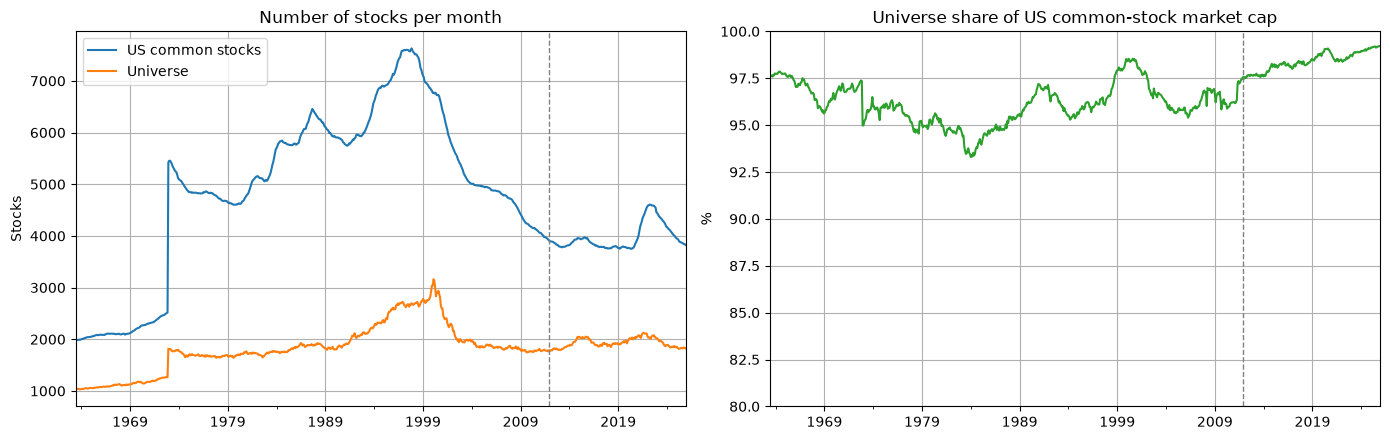

,US common stocks,Universe,Universe share of US common market cap (%)
Decade (formation months),,,
1960s,2086.6000,1091.2000,97.0000
1970s,4144.6000,1555.2000,96.0000
1980s,5612.4000,1792.2000,94.8000
1990s,6694.2000,2366.3000,96.5000
2000s,5191.3000,2033.1000,96.7000
2010s,3880.6000,1883.2000,97.8000
2020s,4153.5000,1963.3000,98.8000


In [25]:
# Universe over time (dates = formation months)
us_common = crsp["is_common"] & crsp["on_exchange"] & period
univ = crsp["in_universe"] & period

universe_ts = pd.DataFrame({
    "US common stocks": crsp[us_common].groupby("date").size(),
    "Universe": crsp[univ].groupby("date").size(),
    "Universe share of US common market cap (%)": 100 * crsp[univ].groupby("date")["me"].sum()
                                                  / crsp[us_common].groupby("date")["me"].sum(),
})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
universe_ts[["US common stocks", "Universe"]].plot(ax=axes[0])
axes[0].set_title("Number of stocks per month")
axes[0].set_ylabel("Stocks")
universe_ts["Universe share of US common market cap (%)"].plot(ax=axes[1], color="tab:green")
axes[1].set_title("Universe share of US common-stock market cap")
axes[1].set_ylabel("%")
axes[1].set_ylim(80, 100)
for ax in axes:
    ax.axvline(IS_END, color="grey", linestyle="--", linewidth=1)   # in-sample / out-of-sample cut-off
    ax.set_xlabel("")
plt.tight_layout()
fig.savefig(OUTPUT / "fig_2_1_universe.png", dpi=150, bbox_inches="tight")
plt.show()

decade_avg = universe_ts.groupby((universe_ts.index.year // 10) * 10).mean().round(1)
decade_avg.index = [f"{d}s" for d in decade_avg.index]
decade_avg.index.name = "Decade (formation months)"
decade_avg

## 2.2 : Summary Statistics of Factors

Annualised mean, volatility, Sharpe ratio, skewness and excess kurtosis of MKT, SMB, HML, RMW, CMA and UMD, for the full sample, in-sample and out-of-sample. UMD's strongly negative skewness is the first sign of the crash problem studied in Part 3.

In [26]:
# Summary statistics. This function is reused for every strategy in the notebook.
def summary_stats(returns):
    """Annualised statistics for monthly (excess) returns, one column per series."""
    r = returns.dropna(how="all")
    cumulative = (1 + r).cumprod()
    drawdown = cumulative / cumulative.cummax() - 1
    return pd.DataFrame({
        "Mean (% p.a.)": 100 * 12 * r.mean(),
        "Vol (% p.a.)": 100 * np.sqrt(12) * r.std(),
        "Sharpe": np.sqrt(12) * r.mean() / r.std(),
        "Skewness": r.skew(),
        "Excess kurtosis": r.kurt(),
        "Worst month (%)": 100 * r.min(),
        "Max drawdown (%)": 100 * drawdown.min(),
        "Months": r.count(),
    })

FACTOR_COLS = ["mkt_rf", "smb", "hml", "rmw", "cma", "umd"]
PERIODS = {"Full sample": (SAMPLE_START, SAMPLE_END),
           "In-sample": (SAMPLE_START, IS_END),
           "Out-of-sample": (OOS_START, SAMPLE_END)}

factor_stats = pd.concat({name: summary_stats(factors.loc[start:end, FACTOR_COLS])
                          for name, (start, end) in PERIODS.items()}, names=["Period", "Factor"])
factor_stats.round(2)

Mean (% p.a.)  Vol (% p.a.)  Sharpe  Skewness  Excess kurtosis  Worst month (%)  Max drawdown (%)  Months
Period        Factor                                                                                                           
Full sample   mkt_rf         7.1300       15.4500  0.4600   -0.5000           1.7500         -23.1900          -55.7500     750
              smb            2.1600       10.4900  0.2100    0.3700           3.1000         -15.5300          -56.4500     750
              hml            3.4300       10.2900  0.3300    0.1000           2.1900         -13.8300          -57.7800     750
              rmw            3.1900        7.6900  0.4100   -0.3200          11.0800         -18.9300          -41.7900     750
              cma            2.8700        7.1500  0.4000    0.2700           1.3900          -7.0600          -27.6300     750
              umd            7.1400       14.4700  0.4900   -1.3000           9.8200         -34.3600          -57.7800     750
In-sample     mkt_rf         5.3000       15.6900  0.3400   -0.5100           1.8700         -23.1900          -55.7500     582
              smb            3.3700       10.7200  0.3100    0.3600           3.5200         -15.5300          -56.4500     582
              hml            4.5500        9.8200  0.4600    0.1000           1.9100         -11.0100          -39.7700     582
              rmw            3.5200        7.8900  0.4500   -0.4900          12.7800         -18.9300          -41.7900     582
              cma            3.8800        7.0300  0.5500    0.2700           1.3500          -6.6300          -17.8800     582
              umd            8.5900       14.9300  0.5800   -1.4300          10.9100         -34.3600          -57.7800     582
Out-of-sample mkt_rf        13.4800       14.4600  0.9300   -0.4400           1.0900         -13.3500          -25.2600     168
              smb           -2.0100        9.5600 -0.2100    0.3300           0.6300          -8.1800          -35.3100     168
              hml           -0.4400       11.7400 -0.0400    0.1800           2.4900         -13.8300          -51.3500     168
              rmw            2.0500        6.9900  0.2900    0.4600           1.1400          -5.2500          -14.0900     168
              cma           -0.6200        7.4800 -0.0800    0.3300           1.6500          -7.0600          -27.6300     168
              umd            2.1200       12.7100  0.1700   -0.7100           2.5600         -16.2100          -25.3800     168

In [28]:
# Check: when does each factor's worst drawdown happen?
r = factors.loc[SAMPLE_START:SAMPLE_END, ["hml", "umd"]]
wealth = (1 + r).cumprod()
dd = wealth / wealth.cummax() - 1
for c in ["hml", "umd"]:
    trough = dd[c].idxmin()
    peak = wealth[c].loc[:trough].idxmax()
    print(f"{c}: peak {peak:%b %Y} -> trough {trough:%b %Y}, drawdown {100 * dd[c].min():.4f}%")

hml: peak Dec 2006 -> trough Sep 2020, drawdown -57.7772%
umd: peak Nov 2008 -> trough Sep 2009, drawdown -57.7765%


The universe grows from about 1,000 stocks in the 1960s to a peak of about 3,100 around 2000, with a jump in December 1972 when NASDAQ stocks enter CRSP, and it covers 93–99% of the market capitalisation of US common stocks throughout the sample.

In-sample (1963–2011), UMD shows the textbook momentum profile: the highest mean among the factors (8.6% per year, Sharpe ratio 0.58), but also the most negative skewness (−1.43), the highest excess kurtosis (10.9), the worst single month (−34.4%, in 2009) and the deepest drawdown (−57.8%). This crash risk is the problem our strategy addresses.

Out-of-sample (2012–2025), UMD earns only 2.1% per year (Sharpe 0.17), in line with the post-publication decline of anomalies documented by McLean & Pontiff (2016); size, value and investment premia are even negative over the same period, while the market had an exceptionally strong run (Sharpe 0.93). This sets a demanding out-of-sample test for H1 and H3. The design is not changed in response to these numbers: all choices remain those fixed in Part 0.

UMD and HML reach almost the same maximum drawdown (−57.8%), but over very different horizons: value lost it slowly from December 2006 to September 2020, while momentum lost it in ten months, from November 2008 to September 2009. The speed of momentum crashes is what makes them hard to survive for an investor, and is precisely what our short-leg rule targets.

> **Part 2 takeaways**
> - **Result:** UMD earns 8.6% per year in-sample (Sharpe 0.58) but with strong crash risk (skewness −1.43, worst month −34.4%, max drawdown −57.8%). Out-of-sample it earns only 2.1% per year (Sharpe 0.17).
> - **Checks passed:** the universe is stable over time (93–99% of US common-stock market cap); factor statistics are in line with the literature.
> - **Warnings / limitations:** the weak out-of-sample momentum premium makes H1 and H3 hard to confirm after 2012; the main contribution is then expected to come from H2 (crash reduction). No design choice is changed because of these numbers.
> - **Next:** Part 3 builds our own WML (row A) and checks it against UMD and the French momentum deciles; `summary_stats` is reused for every strategy.

---
# Part 3 : Baseline Momentum (Row A)

We follow the portfolio analysis steps from lecture 1: define the sort variable, compute breakpoints, group stocks into portfolios, average returns, compute portfolio characteristics, and summarise.

## 3.1 : Standard 12-1 Signal

At the end of each month $t$ (formation date), we compute each stock's cumulative return over the 11 months from $t-11$ to $t-1$:

$$MOM_{i,t} = \prod_{s=t-11}^{t-1}(1 + r_{i,s}) - 1$$

The most recent month $t$ is skipped because one-month returns show short-term reversal, which would contaminate the signal. Relative to the holding month $t+1$, this is the window from $t+1-12$ to $t+1-2$, i.e. the "prior 2–12" definition used by Kenneth French for UMD. A stock needs at least 8 valid monthly returns in the window.

In [32]:
# 12-1 momentum signal at formation date t: cumulative return from t-11 to t-1 (skip month t).
# Computed on a wide table (one row per month, one column per stock), so that missing months
# are real gaps and a rolling window always covers exactly 11 calendar months.
def momentum_signal(returns_wide, first_lag, last_lag, min_obs):
    """Cumulative return from t-first_lag to t-last_lag (first_lag > last_lag >= 1)."""
    log_r = np.log1p(returns_wide.clip(lower=-0.99))   # cap -100% returns: log(0) would be -infinity
    window = first_lag - last_lag + 1
    lagged = log_r.shift(last_lag)                      # row t now holds the return of t-last_lag
    total = lagged.rolling(window, min_periods=min_obs).sum()
    return np.expm1(total)                              # back from log to simple return

ret_wide = crsp.pivot(index="date", columns="PERMNO", values="MthRet")
ret_wide = ret_wide.reindex(pd.date_range(ret_wide.index.min(), ret_wide.index.max(), freq="ME"))

mom_12_1 = momentum_signal(ret_wide, first_lag=11, last_lag=1, min_obs=MIN_OBS_SIGNAL)
crsp = crsp.drop(columns=["mom_12_1"], errors="ignore").merge(
    mom_12_1.stack().dropna().rename("mom_12_1").reset_index().rename(columns={"level_0": "date"}),
    on=["date", "PERMNO"], how="left")

# Sanity check on one stock: recompute the signal by hand for Apple at the end of Dec 2020
aapl = crsp[crsp["PERMNO"] == 14593].set_index("date")["MthRet"]
by_hand = (1 + aapl.loc["2020-01-31":"2020-11-30"]).prod() - 1      # Jan-Nov 2020 = t-11 ... t-1
in_table = crsp.loc[(crsp["PERMNO"] == 14593) & (crsp["date"] == "2020-12-31"), "mom_12_1"].iloc[0]
print(f"Apple, formation Dec 2020: by hand {by_hand:.4f} | in table {in_table:.4f}")
print(f"Universe stock-months with a valid 12-1 signal: "
      f"{100 * crsp.loc[crsp['in_universe'] & period, 'mom_12_1'].notna().mean():.1f}%")
del ret_wide

Apple, formation Dec 2020: by hand 0.6357 | in table 0.6357
Universe stock-months with a valid 12-1 signal: 96.6%


## 3.2 : NYSE Decile Breakpoints & Sorts

We use 10 portfolios, with breakpoints computed from NYSE stocks only and then applied to the whole universe. As in lecture 1, NYSE breakpoints avoid sorts dominated by tiny but numerous AMEX and NASDAQ stocks. This is also how UMD is built, which makes the validation in Part 3.5 meaningful.

In [33]:
# NYSE decile breakpoints: each month t, the 10th, 20th, ..., 90th percentiles of the signal among
# NYSE common stocks with valid data (as in Kenneth French's UMD and lecture 1), then applied to
# every stock in our universe. Uses only month-t information.
def nyse_breakpoints(df, signal, n_port=N_PORT):
    nyse = df[df["is_common"] & df["is_nyse"] & df["has_data"] & df[signal].notna()]
    qs = np.linspace(0, 1, n_port + 1)[1:-1]            # 0.1, 0.2, ..., 0.9
    return nyse.groupby("date")[signal].quantile(qs).unstack()

def assign_portfolios(df, signal, breakpoints):
    """Portfolio 1 = signal <= first breakpoint, ..., portfolio 10 = above the 9th breakpoint."""
    port = pd.Series(np.nan, index=df.index)
    for date, idx in df.groupby("date").groups.items():
        if date in breakpoints.index:
            bp = breakpoints.loc[date].to_numpy()
            x = df.loc[idx, signal].to_numpy()
            port.loc[idx] = np.where(np.isnan(x), np.nan, np.searchsorted(bp, x, side="left") + 1)
    return port

bp_12_1 = nyse_breakpoints(crsp, "mom_12_1")
univ_sig = crsp["in_universe"] & crsp["mom_12_1"].notna() & period
crsp["port_12_1"] = np.nan
crsp.loc[univ_sig, "port_12_1"] = assign_portfolios(crsp[univ_sig], "mom_12_1", bp_12_1)

# Check against Kenneth French's NYSE momentum breakpoints (percent). His file may be dated by
# formation or holding month, so we compare both alignments: the right one should match closely.
ours = 100 * bp_12_1[[0.1, 0.5, 0.9]]
ours.columns = ["p10", "p50", "p90"]
for label, shift in [("same month", 0), ("French dated one month later", 1)]:
    french = mom_bp[["p10", "p50", "p90"]].shift(-shift)
    both = ours.join(french.add_suffix("_french")).loc[SAMPLE_START:SAMPLE_END].dropna()
    corr = [both[c].corr(both[c + "_french"]) for c in ["p10", "p50", "p90"]]
    print(f"Breakpoints vs French ({label}): correlation p10 {corr[0]:.3f}, p50 {corr[1]:.3f}, p90 {corr[2]:.3f}")

counts = crsp[univ_sig].groupby(["date", "port_12_1"]).size().unstack()
print("\nAverage number of universe stocks per decile:")
counts.mean().round(0).to_frame("Stocks").T

Breakpoints vs French (same month): correlation p10 0.998, p50 0.998, p90 0.998
Breakpoints vs French (French dated one month later): correlation p10 0.929, p50 0.900, p90 0.879

Average number of universe stocks per decile:


port_12_1,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,7.0000,8.0000,9.0000,10.0000
Stocks,120.0000,155.0000,165.0000,171.0000,175.0000,178.0000,180.0000,187.0000,198.0000,252.0000


## 3.3 : Decile Portfolios & WML

We form equal- and value-weighted decile portfolios, held for one month and then rebalanced. The baseline strategy goes long decile 10 (winners) and short decile 1 (losers):

$$WML_{t+1} = r^{W}_{t+1} - r^{L}_{t+1}$$

We report the average return and standard deviation of all ten deciles and of 10−1, plus the cumulative growth of each decile, to check that the relationship is roughly monotonic.

,VW mean (%),VW std (%),EW mean (%),EW std (%)
d1,0.2800,8.1300,0.2900,8.5400
d2,0.7800,6.4800,0.7900,6.5000
d3,0.9000,5.3800,0.9400,5.6900
d4,0.9500,4.8100,0.9700,5.1800
d5,0.8800,4.5000,1.0500,4.8800
d6,0.9500,4.5000,1.0400,4.7400
d7,0.9600,4.3700,1.1400,4.7100
d8,1.0600,4.4300,1.1700,4.8100
d9,1.0700,4.7400,1.2900,5.1300
d10,1.4500,6.0400,1.5500,6.6400


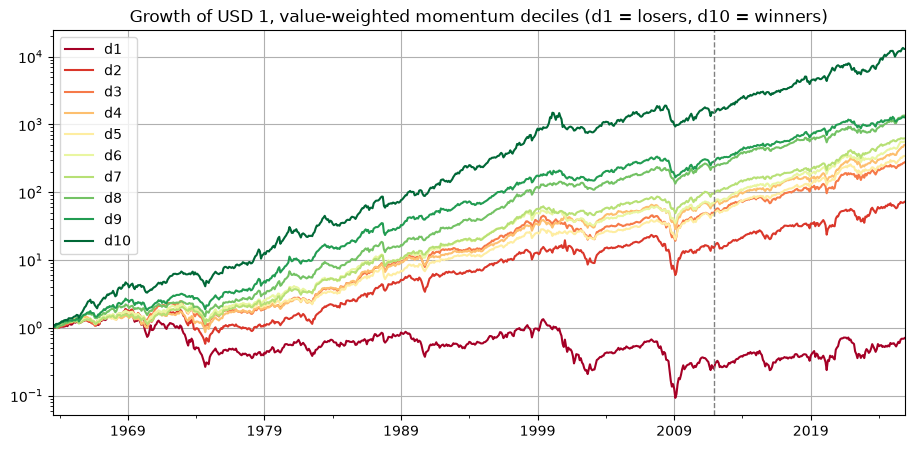

In [34]:
# Decile portfolio returns. Formed at the end of month t, held during month t+1 (dated t+1).
# Value weights use market cap at the end of month t (lecture 1); equal weights shown for comparison.
def portfolio_returns(df, port_col, weight_col="me"):
    d = df[df[port_col].notna() & df["ret_next"].notna()]
    d = d.assign(w_ret=d["ret_next"] * d[weight_col])
    g = d.groupby(["date", port_col])
    vw = (g["w_ret"].sum() / g[weight_col].sum()).unstack()
    ew = g["ret_next"].mean().unstack()
    for x in (vw, ew):
        x.index = x.index + pd.offsets.MonthEnd(1)      # date by holding month
        x.columns = [f"d{int(c)}" for c in x.columns]
    return vw.loc[SAMPLE_START:SAMPLE_END], ew.loc[SAMPLE_START:SAMPLE_END]

dec_vw, dec_ew = portfolio_returns(crsp, "port_12_1")
wml = pd.DataFrame({"WML (VW)": dec_vw["d10"] - dec_vw["d1"],
                    "WML (EW)": dec_ew["d10"] - dec_ew["d1"]})

# Average monthly return and volatility of each decile and of 10-1 (lecture 1 format)
dec_table = pd.DataFrame({
    "VW mean (%)": 100 * dec_vw.mean(), "VW std (%)": 100 * dec_vw.std(),
    "EW mean (%)": 100 * dec_ew.mean(), "EW std (%)": 100 * dec_ew.std(),
})
dec_table.loc["10-1"] = [100 * wml["WML (VW)"].mean(), 100 * wml["WML (VW)"].std(),
                         100 * wml["WML (EW)"].mean(), 100 * wml["WML (EW)"].std()]
display(dec_table.round(2))

# Cumulative growth of USD 1 in each value-weighted decile (log scale)
ax = (1 + dec_vw).cumprod().plot(logy=True, figsize=(11, 5), colormap="RdYlGn",
                                 title="Growth of USD 1, value-weighted momentum deciles (d1 = losers, d10 = winners)")
ax.axvline(IS_END, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("")
plt.savefig(OUTPUT / "fig_3_3_deciles.png", dpi=150, bbox_inches="tight")
plt.show()

Average returns rise almost monotonically from the loser decile (0.28% per month, value-weighted) to the winner decile (1.45%), and the 10-1 portfolio earns 1.17% per month value-weighted (1.26% equal-weighted), in line with the 1.07–1.13% reported in lecture 3 for value-weighted momentum. One dollar invested in the winner decile in 1963 grows to over USD 10,000 by 2025, while the loser decile ends below its starting value.

## 3.4 : Decile Characteristics

For each decile: average number of stocks, average market capitalisation, and average signal value (sanity check that the sort works). This shows where in the size distribution the winners and losers sit, which matters for trading costs.

In [35]:
# Decile characteristics (lecture 1): averages over formation months
d = crsp[univ_sig]
g = d.groupby(["date", "port_12_1"])
char_ts = pd.DataFrame({
    "Stocks": g.size(),
    "Avg market cap (USD bn)": g["me"].mean() / 1000,
    "Median market cap (USD bn)": g["me"].median() / 1000,
    "Share of universe market cap (%)": 100 * g["me"].sum() / d.groupby("date")["me"].sum(),
    "Median past 12-1 return (%)": 100 * g["mom_12_1"].median(),
    "NYSE stocks (%)": 100 * g["is_nyse"].mean(),
})
dec_char = char_ts.groupby("port_12_1").mean()
dec_char.index = [f"d{int(i)}" for i in dec_char.index]
dec_char.round(1)

,Stocks,Avg market cap (USD bn),Median market cap (USD bn),Share of universe market cap (%),Median past 12-1 return (%),NYSE stocks (%)
d1,119.8000,2.2000,0.8000,3.6000,-34.8000,60.6000
d2,154.8000,4.0000,1.0000,7.2000,-18.4000,66.5000
d3,164.8000,5.0000,1.2000,9.1000,-8.6000,69.1000
d4,170.7000,6.0000,1.4000,10.4000,-1.0000,69.9000
d5,175.3000,6.4000,1.5000,11.0000,5.7000,70.1000
d6,177.6000,6.9000,1.6000,11.4000,12.4000,70.4000
d7,180.4000,7.1000,1.6000,11.9000,19.7000,69.6000
d8,186.6000,7.2000,1.6000,12.5000,28.7000,68.0000
d9,198.1000,7.3000,1.6000,12.4000,42.3000,64.4000
d10,251.5000,5.1000,1.1000,10.5000,79.7000,51.2000


Losers and winners are smaller and less often NYSE-listed than stocks in the middle deciles (median market cap USD 0.8 billion and 1.1 billion, against about 1.5 billion), and the loser decile holds only 120 stocks on average against 252 for winners, because many large losers fall below our price and size filters. The median past return ranges from −35% in decile 1 to +80% in decile 10.

## 3.5 : Validation Against UMD

Key quality check: value-weighted WML should have a correlation of about 0.9 with Kenneth French's UMD (not 1, since UMD is built from 2×3 size-momentum sorts) and a similar mean. If not, there is a problem in the data or the construction, and we do not move on.

Mean (% p.a.)  Vol (% p.a.)  Sharpe  Skewness  Excess kurtosis  Worst month (%)  Max drawdown (%)  Months
Period        Series                                                                                                                   
Full sample   WML (ours, VW)        14.0600       24.1200  0.5800   -0.9300           3.8300         -41.0600          -71.5100     750
              UMD (French)           7.1400       14.4700  0.4900   -1.3000           9.8200         -34.3600          -57.7800     750
In-sample     WML (ours, VW)        16.6500       23.4400  0.7100   -0.9400           4.6400         -41.0600          -71.5100     582
              UMD (French)           8.5900       14.9300  0.5800   -1.4300          10.9100         -34.3600          -57.7800     582
Out-of-sample WML (ours, VW)         5.1100       26.2600  0.1900   -0.8800           1.8900         -28.6400          -59.2700     168
              UMD (French)           2.1200       12.7100  0.1700   -0.7100           2.5600         -16.2100          -25.3800     168

Correlation WML vs UMD: 0.887 | regression WML = 0.29% + 1.48 x UMD, R2 = 0.79


,Ours mean (%),French mean (%),Correlation
d1,0.2830,0.3360,0.9780
d2,0.7820,0.7760,0.9940
d3,0.8970,0.9150,0.9930
d4,0.9470,0.9610,0.9920
d5,0.8830,0.9030,0.9900
d6,0.9490,0.9700,0.9900
d7,0.9570,0.9660,0.9920
d8,1.0630,1.0740,0.9940
d9,1.0710,1.0980,0.9950
d10,1.4540,1.4840,0.9970


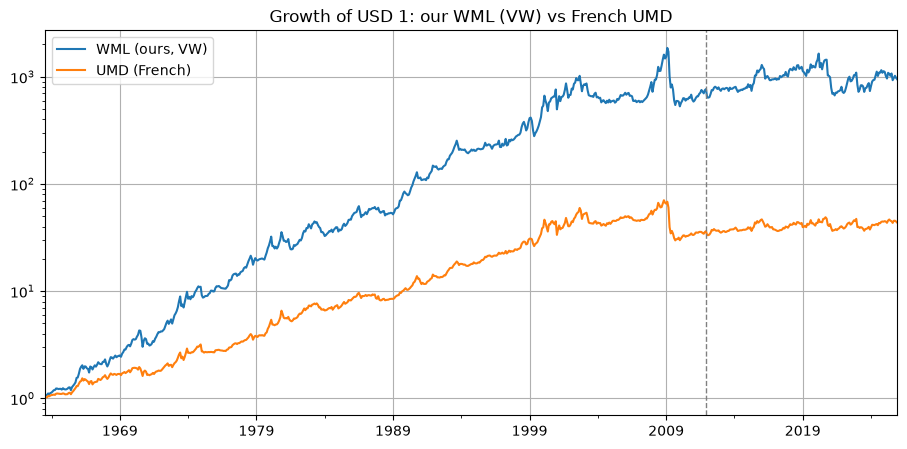

In [36]:
# Validation: our value-weighted WML against Kenneth French's UMD and his momentum deciles
val = pd.DataFrame({"WML (ours, VW)": wml["WML (VW)"], "UMD (French)": factors["umd"]}).dropna()

# 1. Same statistics over the same months
display(pd.concat({name: summary_stats(val.loc[start:end]) for name, (start, end) in PERIODS.items()},
                  names=["Period", "Series"]).round(2))

# 2. Correlation and regression of WML on UMD
ols = sm.OLS(val["WML (ours, VW)"], sm.add_constant(val["UMD (French)"])).fit()
print(f"Correlation WML vs UMD: {val.corr().iloc[0, 1]:.3f} | "
      f"regression WML = {100 * ols.params['const']:.2f}% + {ols.params['UMD (French)']:.2f} x UMD, R2 = {ols.rsquared:.2f}")

# 3. Decile by decile against French's value-weighted momentum deciles
both = dec_vw.join(french_mom10.add_suffix("_french"), how="inner")
dec_compare = pd.DataFrame({
    "Ours mean (%)": [100 * both[f"d{k}"].mean() for k in range(1, 11)],
    "French mean (%)": [100 * both[f"d{k}_french"].mean() for k in range(1, 11)],
    "Correlation": [both[f"d{k}"].corr(both[f"d{k}_french"]) for k in range(1, 11)],
}, index=[f"d{k}" for k in range(1, 11)])
display(dec_compare.round(3))

# 4. Cumulative returns, WML vs UMD
ax = (1 + val).cumprod().plot(logy=True, figsize=(11, 5), title="Growth of USD 1: our WML (VW) vs French UMD")
ax.axvline(IS_END, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("")
plt.savefig(OUTPUT / "fig_3_5_wml_vs_umd.png", dpi=150, bbox_inches="tight")
plt.show()

Our baseline WML is validated against Kenneth French's data. Its correlation with UMD is 0.887, and decile by decile our value-weighted portfolios correlate between 0.978 and 0.997 with French's momentum deciles, with nearly identical average returns (e.g. 1.454% against 1.484% per month for decile 10). Our NYSE breakpoints also match French's with a correlation of 0.998 (Part 3.2), which confirms the signal window from $t-11$ to $t-1$.

WML has a higher mean and volatility than UMD (14.1% and 24.1% per year, against 7.1% and 14.5%; regression beta 1.48) because it is the spread between the extreme deciles, while UMD averages the top and bottom 30% across small and big stocks. Its Sharpe ratio is similar (0.58 against 0.49). Out-of-sample, WML is weak as well (Sharpe 0.19), consistent with UMD (0.17). This value-weighted 12-1 WML is row A of the cascade.

## 3.6 : Momentum Crashes in Our Data

Before any correction, we document the problem in our own sample: the ten worst months of WML, its skewness, and the returns of the long and short legs from March to May 2009. The point is to show that crashes come from the short leg: after a market decline the losers are high-beta stocks that rebound sharply when the market recovers.

This analysis motivates the short-leg rule in Part 6 and makes the strategy's logic our own rather than a replication.

Ten worst WML months (%):


,WML,Long leg (winners - rf),Short leg (rf - losers),Market (mkt - rf)
date,,,,
Apr 2009,-41.1000,-0.5000,-40.5000,10.2000
Jan 2001,-34.7000,-7.0000,-27.7000,3.2000
Nov 2020,-28.6000,10.4000,-39.0000,12.4000
Apr 2020,-25.4000,14.4000,-39.7000,13.6000
Jan 2023,-23.1000,0.5000,-23.6000,6.6000
May 2009,-21.3000,1.5000,-22.8000,5.2000
Aug 2009,-20.7000,0.3000,-21.0000,3.3000
Feb 2021,-20.4000,-2.8000,-17.6000,2.8000
Jan 2008,-18.8000,-13.2000,-5.6000,-6.3000


March - May 2009 (%):


,WML,Long leg (winners - rf),Short leg (rf - losers),Market (mkt - rf)
date,,,,
Mar 2009,-7.9000,5.4000,-13.3000,9.0000
Apr 2009,-41.1000,-0.5000,-40.5000,10.2000
May 2009,-21.3000,1.5000,-22.8000,5.2000
Total (compounded),-57.3000,6.4000,-60.2000,26.3000


WML skewness: -0.93 | Of the 20 worst WML months, the short leg lost more than the long leg in 90%, and the market was up in 90%.


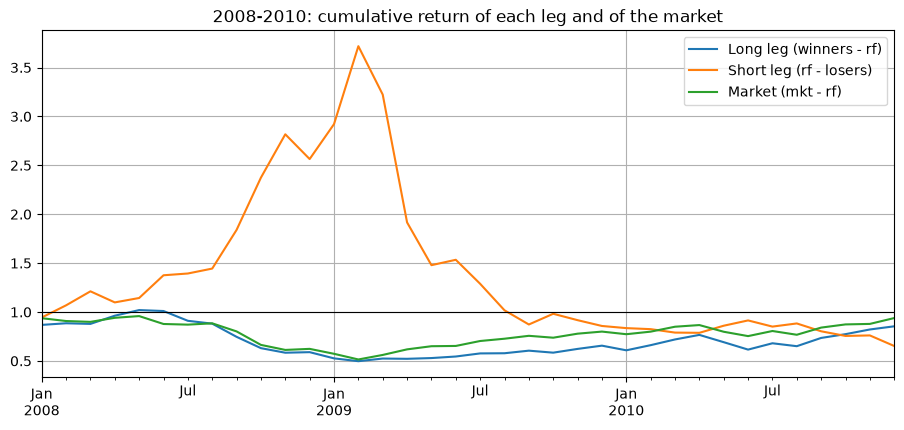

In [37]:
# Momentum crashes in our data: where do the losses come from?
legs = pd.DataFrame({
    "WML": wml["WML (VW)"],
    "Long leg (winners - rf)": dec_vw["d10"] - factors["rf"],
    "Short leg (rf - losers)": factors["rf"] - dec_vw["d1"],   # what the short position earns
    "Market (mkt - rf)": factors["mkt_rf"],
}).loc[SAMPLE_START:SAMPLE_END]

# 1. Ten worst months of WML, with the contribution of each leg (WML = long leg + short leg)
print("Ten worst WML months (%):")
worst10 = 100 * legs.nsmallest(10, "WML")
worst10.index = worst10.index.strftime("%b %Y")
display(worst10.round(1))

# 2. The 2009 momentum crash, month by month
print("March - May 2009 (%):")
crash = 100 * legs.loc["2009-03-31":"2009-05-31"]
crash.index = crash.index.strftime("%b %Y")
crash.loc["Total (compounded)"] = 100 * ((1 + legs.loc["2009-03-31":"2009-05-31"]).prod() - 1)
display(crash.round(1))

# 3. Skewness and share of the worst months caused mainly by the short leg
worst = legs.nsmallest(20, "WML")
share_short = (worst["Short leg (rf - losers)"] < worst["Long leg (winners - rf)"]).mean()
print(f"WML skewness: {legs['WML'].skew():.2f} | Of the 20 worst WML months, the short leg lost more "
      f"than the long leg in {100 * share_short:.0f}%, and the market was up in "
      f"{100 * (worst['Market (mkt - rf)'] > 0).mean():.0f}%.")

# 4. Picture: cumulative returns around the 2008-2009 crisis
ax = (1 + legs.loc["2008-01-31":"2010-12-31", ["Long leg (winners - rf)", "Short leg (rf - losers)", "Market (mkt - rf)"]]
      ).cumprod().plot(figsize=(11, 4.5), title="2008-2010: cumulative return of each leg and of the market")
ax.axhline(1, color="black", linewidth=0.8)
ax.set_xlabel("")
plt.savefig(OUTPUT / "fig_3_6_crash_2009.png", dpi=150, bbox_inches="tight")
plt.show()

Momentum crashes come from the short leg, during market rebounds. In April 2009, WML lost 41.1%, of which 40.5 points came from the short leg, while the market rose 10.2%. Over March–May 2009, winners still earned 6.4% but shorting losers lost 60.2%, so that WML lost 57.3% while the market gained 26.3%. The pattern is systematic: in 90% of the 20 worst WML months the short leg lost more than the long leg, and in 90% of them the market was up. The same mechanism appears in recent crashes (April and November 2020, January 2023). WML's skewness is −0.93.

This motivates our rule in Part 6: after a market decline, losers are high-beta stocks that rebound sharply when the market recovers, so reducing the short leg in bear markets with high loser volatility targets exactly the months where momentum crashes.

> **Part 3 takeaways**
> - **Result:** our value-weighted 12-1 WML (row A) earns 16.7% per year in-sample (Sharpe 0.71) but with severe crash risk (worst month −41.1% in April 2009, max drawdown −71.5%, skewness −0.94); out-of-sample it earns 5.1% per year (Sharpe 0.19).
> - **Checks passed:** NYSE breakpoints match French's (correlation 0.998); decile returns match French's momentum deciles (correlation 0.978–0.997); WML–UMD correlation 0.887; Apple's signal recomputed by hand.
> - **Warnings / limitations:** the signal window is $t-11$ to $t-1$ at formation date $t$ (French's "prior 2–12" relative to the holding month); v2's notation was corrected accordingly. Monthly returns of −100% are capped at −99% inside the signal (log of zero).
> - **Next:** crashes come from the short leg during market rebounds (90% of the 20 worst months), which motivates the short-leg rule (Part 6). Before that, Part 4 needs the group's decision on the cost model.

---
# Part 4 : Turnover & Transaction Cost Framework

The same cost model is applied to every row of every table, so no version of the strategy is favoured. It is defined here because the signal selection in Part 5 already uses net returns. The approach follows lecture 3.

## 4.1 : Portfolio Turnover

Between rebalancing dates, weights drift with price returns: $w^{*}_{i,t+1} = w_{i,t}\,(1 + Rx_{i,t+1})$. The trade needed to reach the new target weights is:

$$\Delta w_{i,t+1} = w_{i,t+1} - \frac{w^{*}_{i,t+1}}{\sum_j w^{*}_{j,t+1}}$$

$$\text{Turn}_{t+1} = \sum_i \left|\Delta w_{i,t+1}\right|$$

This includes stocks that stay, exit and enter. A full change of composition is 200% for one leg, so the maximum for a long-short portfolio is 400%. For scaled versions (our rule, Moreira-Muir), turnover also includes trades caused by changes in $k_t$ or in leverage, not only changes in composition.

## 4.2 : Cost Model: Spread + Price Impact

Each trade pays half the bid-ask spread plus a price impact:

$$\text{Cost}_{t} = \sum_i \left|\Delta w_{i,t}\right| \left(\frac{s_{i,t}}{2} + \lambda_i \frac{\text{Trade size}_{i,t}}{\text{ADV}_{i,t}}\right)$$

- **Spread $s_{i,t}$** : from CRSP closing bid and ask quotes where available, otherwise the Corwin & Schultz (2012) high-low estimator. As in lecture 3, remaining missing values are replaced with the mean spread of the stock's size category.
- **Price impact** : $\lambda$ = 2.5, 1.5 and 1.0 for micro, small and large stocks, i.e. 25, 15 and 10 bp for a trade of 1% of average daily volume (ADV), as in lecture 3.
- **Trade size** depends on an assumed fund size (base case to be fixed in Part 9, e.g. \$100 million), with a larger fund as sensitivity.

## 4.3 : Fixed-Cost Scenarios

As a simple, model-free cross-check, we also apply fixed costs of 10, 25 and 50 bp per unit of turnover to every row. These are reported in the robustness section (Part 14.1).

## 4.4 : Sanity Check Against Lecture 3

Our baseline numbers should be in the same range as the momentum results shown in lecture 3 for non-micro-cap, value-weighted stocks: about 149% monthly turnover for 10−1, and about 82% under the 10%/20% rule. Large deviations point to an error in the turnover calculation.

## 4.5 : Short-Selling Limitation

Stock borrowing fees are not modelled. This is stated as a limitation, and the short leg's contribution to returns is reported separately in Part 10.5.

---
# Part 5 : Signal Selection (In-Sample, Row B)

## 5.1 : Candidate Signals

Four candidate signals, all using the same NYSE decile sort and long-short construction as Part 3:

| Signal | Formation window (formation date $t$) | Source |
|--------|------------------|--------|
| Standard 12-1 | $t-11$ to $t-1$ | Jegadeesh & Titman (1993) |
| Intermediate 12-7 | $t-11$ to $t-6$ | Novy-Marx (2012) |
| Recent 6-2 | $t-5$ to $t-1$ | Novy-Marx (2012); Goyal & Wahal (2015) |
| Residual 12-1 | FF3 residuals $t-11$ to $t-1$, scaled by their volatility | Blitz, Huij & Martens (2011) |

The names follow the literature, where windows are stated relative to the holding month: "12-7" means months $t+1-12$ to $t+1-7$.

## 5.2 : Residual Momentum

For each stock, we estimate over the previous 36 months:

$$r_{i,s} - r_{f,s} = \alpha_i + \beta_i\, MKT_s + s_i\, SMB_s + h_i\, HML_s + \varepsilon_{i,s}$$

The signal is the sum of residuals from $t-11$ to $t-1$, divided by their standard deviation:

$$RMOM_{i,t} = \frac{\sum_{s=t-11}^{t-1} \hat{\varepsilon}_{i,s}}{\sigma(\hat{\varepsilon}_i)}$$

At least 24 of the 36 monthly returns must be available.

## 5.3 : In-Sample Portfolio Comparison

For each of the four signals, on 1963–2011 only: annualised return, volatility, gross and net Sharpe ratio, maximum drawdown, skewness and average turnover.

## 5.4 : Fama-MacBeth Horse Race

Portfolio sorts look at one signal at a time. Fama-MacBeth regressions (lecture 1) let us control for other characteristics and test the signals against each other, which is the format Novy-Marx (2012) and Goyal & Wahal (2015) use for the echo debate. Each month we run the cross-sectional regression:

$$R_{i,t+1} = \gamma_{0,t} + \gamma_{1,t}\,X_{i,t} + \gamma_{2,t}\log(ME_{i,t}) + \gamma_{3,t}\,R_{i,t} + e_{i,t+1}$$

where $X_{i,t}$ contains the candidate signals and $R_{i,t}$ is the previous month's return (short-term reversal). Book-to-market is added as a control if accounting data are available. We report the time-series averages $\bar{\gamma} = \frac{1}{T}\sum_t \gamma_t$ with their t-statistics, on 1963–2011 only.

This is supporting evidence. The selection itself follows the pre-registered rule in 5.5.

## 5.5 : Pre-Registered Selection Rule

The rule is fixed before any result is seen: we keep the signal with the highest in-sample net Sharpe ratio (cost model of Part 4.2). If the best signal beats the standard 12-1 by less than 0.05, we keep the 12-1 as the simplest choice.

The selected signal defines row B. The full comparison of all four signals after 2012 is reported in Part 10.2 regardless of the winner. We only test the US part of the echo debate.

_Interpretation: to be written once results are in._

---
# Part 6 : Short-Leg Crash Protection (Our Rule, Row C)

This is our own contribution. Daniel & Moskowitz (2016) scale the whole WML portfolio using forecasts of its mean and variance, and Cooper, Gutierrez & Hameed (2004) condition momentum on the market state. Our rule differs: it acts on the short leg only, uses two observable conditions with no forecasting model, leaves the long leg untouched, and is tested out of sample.

## 6.1 : Bear Market Indicator

$\text{Bear}_t = 1$ if the cumulative excess market return over the past 24 months (up to $t$) is negative. The 24-month window follows Daniel & Moskowitz (2016).

## 6.2 : Loser Volatility Indicator

$\text{HighVol}_t = 1$ if the realised volatility of the loser portfolio's daily returns over month $t$ is above its median, where the median is computed on an expanding window using data up to $t$ only (no look-ahead).

## 6.3 : Short-Leg Scaling

When both conditions hold, the short leg is reduced:

$$k_t = 1 - \delta \cdot \mathbf{1}[\text{Bear}_t] \cdot \mathbf{1}[\text{HighVol}_t]$$

$$r^{\text{final}}_{t+1} = \left(r^{W}_{t+1} - r_{f,t+1}\right) - k_t\left(r^{L}_{t+1} - r_{f,t+1}\right)$$

$\delta = 0.5$ is fixed a priori, not optimised.

Consequence to report: when $k < 1$ the portfolio is net long the market, precisely in bear markets. This helps during a rebound (2009) and hurts if the market keeps falling (late 2008). We address this with the conditional-beta test in Part 11.3 and a beta-hedged variant in the appendix (Part 14.3).

## 6.4 : Trigger Count & Episodes

Number of months the rule is active, in-sample and out-of-sample, and the list of episodes (dates). If the rule rarely or never triggers after 2012, the report says so clearly.

## 6.5 : Sensitivity to δ (In-Sample Only)

Results for $\delta \in \{0.25, 0.5, 0.75, 1\}$ on 1963–2011, shown as sensitivity only. The base value stays at 0.5 whatever the results.

## 6.6 : Does the Trigger Predict Crashes? (Predictive Regression & OOS $R^2$)

Our rule is a timing signal, so we evaluate it the way lecture 4 evaluates market predictors. The predictive regression is:

$$r^{L}_{t+1} - r_{f,t+1} = a + b\,\mathbf{1}[\text{Bear}_t]\,\mathbf{1}[\text{HighVol}_t] + e_{t+1}$$

A positive $b$ means losers rebound more after a trigger, which is the risk our rule avoids. In-sample, we report $b$, its t-statistic and $R^2$. Out of sample, we run the lecture 4 horse race: investor A re-estimates the regression each month on an expanding window, while investor B uses the historical mean. We report

$$R^2_{OOS} = 1 - \frac{\sum_t (E^{A}_t)^2}{\sum_t (E^{B}_t)^2}$$

A positive $R^2_{OOS}$ means the trigger beats the naive benchmark in real time.

_Interpretation: to be written once results are in._

---
# Part 7 : Turnover Buffer (Row D, Final Strategy)

## 7.1 : Buy/Hold Spread Rule

This is the 10%/20% cost-mitigation rule from lecture 3 (Novy-Marx & Velikov 2016). A stock enters the long leg when it reaches decile 10 and stays as long as it is in deciles 9–10. Symmetrically, it enters the short leg at decile 1 and stays while in deciles 1–2. It works because stocks just outside the top decile have almost the same expected return as those just inside, so holding them is a cheap substitute for trading. Buffer widths are fixed a priori.

## 7.2 : Turnover Reduction

We compare average monthly turnover, spread costs, price impact and net returns of row C (no buffer) and row D (buffer). The signal is almost unchanged but the number of trades should fall sharply, close to halving as in lecture 3.

_Interpretation: to be written once results are in._

---
# Part 8 : Competitor: Real-Time Moreira-Muir Volatility Scaling (Row E)

Moreira & Muir (2017) is kept as a competitor that our rule must beat, not as a layer. Row E = row B + real-time volatility scaling + turnover buffer, so it is directly comparable with row D.

## 8.1 : Realised Variance

Realised variance of the long-short portfolio over month $t$, from its daily returns:

$$\sigma^2_t = \sum_{d \in t}\left(r_d - \bar{r}_t\right)^2$$

## 8.2 : Scaled Returns with Real-Time $c_t$

$$r^{*}_{t+1} = \frac{c_t}{\sigma^2_t}\, r_{t+1}$$

$c_t$ is estimated on an expanding window using data up to $t$ only, so the managed strategy targets the same volatility as the unmanaged one without using future information. Leverage $c_t/\sigma^2_t$ is capped at 2.

The full-sample $c$ version goes in the appendix, flagged as having look-ahead bias. The report cites the finding that volatility-management gains largely disappear in real time and after costs (Cederburg, O'Doherty, Wang & Yan 2020; Barroso & Detzel 2021).

## 8.3 : Turnover Including Leverage Changes

Turnover for row E includes the trades caused by month-to-month changes in leverage, using the same cost model as Part 4.

---
# Part 9 : Design Freeze

Before any out-of-sample number is computed, all design choices are recorded here and committed to the code repository:

| Parameter | Value |
|-----------|-------|
| Selected signal | _from Part 5.5_ |
| Bear indicator window | 24 months |
| Loser volatility threshold | Expanding median |
| δ | 0.5 |
| Buffer | Enter 10 / hold 9–10; enter 1 / hold 1–2 |
| Moreira-Muir leverage cap | 2 |
| Cost model | Half-spread + price impact (λ = 2.5 / 1.5 / 1.0) |
| Assumed fund size | _to be fixed_ |

From this point on, no parameter is changed. The out-of-sample panel in Part 10 is computed with exactly these settings.

---
# Part 10 : Main Results: Cascade Table

## 10.1 : Cascade Table

One panel for 1963–2011 (in-sample) and one for 2012–2025 (out-of-sample), with the same rows and columns:

| Row | Version |
|-----|---------|
| A | Standard 12-1 momentum (benchmark) |
| B | A with the selected signal (Part 5) |
| C | B + our short-leg rule (Part 6) |
| D | C + turnover buffer (Part 7): **final strategy** |
| E | B + real-time Moreira-Muir + buffer (competitor, Part 8) |

Columns: annualised return and volatility, Sharpe ratio (with bootstrap confidence interval from Part 12.4), maximum drawdown, skewness, worst month, average monthly turnover, market beta, and net return and Sharpe after costs. The D vs E comparison puts our rule head-to-head with the literature's.

_Interpretation: to be written once results are in._

## 10.2 : Out-of-Sample Signal Comparison

All four candidate signals after 2012, reported in full regardless of which one was selected. This is our out-of-sample answer to the echo debate (H1).

_Interpretation: to be written once results are in._

## 10.3 : Cumulative Returns & Drawdowns

Cumulative log returns and drawdown paths of rows A to E over the full sample, with the in-sample / out-of-sample cut-off and NBER recessions shaded.

## 10.4 : 2009 Case Study

Monthly returns of each version from March to May 2009, the largest momentum crash in the sample, split into long-leg and short-leg contributions. This is the most direct visual test of whether our rule works when it matters.

_Interpretation: to be written once results are in._

## 10.5 : Long-Leg vs Short-Leg Contribution

For rows A to E, we split the return into the long leg (winners minus risk-free) and the short leg (risk-free minus losers), in-sample and out-of-sample, with each leg's Sharpe ratio and share of total return. Since borrowing fees are not modelled, this shows how much of the result depends on the short side, and how much would remain for a long-only or short-constrained investor.

_Interpretation: to be written once results are in._

---
# Part 11 : Alphas & Market Timing Test

## 11.1 : Factor Model Alphas

Following lecture 2, we run time-series regressions of the excess return of each row on the factors:

$$r_t = \alpha + \beta' f_t + \varepsilon_t$$

Models: CAPM, Fama-French 3, Carhart (FF3 + UMD), FF5 + UMD and the Hou-Xue-Zhang q-factor model. FF5 + UMD is the main model because it controls for momentum itself. The q-factor model is a demanding test, since lecture 2 shows it can largely explain momentum through its profitability factor.

t-statistics use Newey-West standard errors with 6 lags. Following Harvey, Liu & Zhu (2016), significance is judged against $t > 3$ rather than 1.96 to account for data mining. The key test is the alpha of row D against FF5 + UMD (H3).

## 11.2 : Incremental Value

To isolate the contribution of each step, we regress C on B and D on C. A significant intercept means the step adds something the previous row does not already capture.

## 11.3 : Conditional Beta Test

Since our rule changes market exposure in bear markets, a static CAPM alpha is not enough. We estimate:

$$r_t = \alpha + \beta\, MKT_t + \beta_B\, \mathbf{1}[\text{Bear}_{t-1}]\, MKT_t + \varepsilon_t$$

and check whether the rule's gain survives when beta is allowed to differ in bear months (H2).

_Interpretation: to be written once results are in._

---
# Part 12 : Placebo & Bootstrap Tests

Shuffling the order of a strategy's monthly returns changes neither its mean, volatility nor Sharpe ratio, so on its own it tests nothing. We use four versions that do work.

## 12.1 : Timing Placebo (Tests Our Rule)

Keep the same number of triggered months but place them at random dates, then recompute row C. Repeat 1,000 times. If the true timing beats random timing, the rule adds value.

## 12.2 : Cross-Sectional Placebo (Tests the Signal)

Each month, randomly reassign the signal across stocks and rebuild the long-short portfolio. Repeat 1,000 times and compare the distribution with the true strategy.

## 12.3 : Time-Shuffle Test

Shuffle the months to destroy volatility clustering, then recompute rows C and E. If each rule's benefit disappears, it genuinely comes from timing.

## 12.4 : Block Bootstrap Confidence Intervals

Block bootstrap with 12-month blocks to obtain confidence intervals for the Sharpe ratio and maximum drawdown of rows A to E. These intervals feed the cascade table in Part 10.1.

_Interpretation: to be written once results are in._

---
# Part 13 : Portfolio Implications

The investment committee does not hold the strategy on its own: the question is what it adds to the portfolio the firm already holds. This Part translates the results into those terms.

## 13.1 : Correlation with Existing Exposures

Correlation of row D with the market, value (HML), the other Fama-French factors and UMD, in-sample and out-of-sample. We also report the strategy's worst calendar year next to the market's worst year.

## 13.2 : Adding the Strategy to a Market Portfolio

We combine the market portfolio with rows A and D and compare the Sharpe ratio, volatility and maximum drawdown of the combined portfolio. We also report the weight on the strategy that maximises the in-sample Sharpe ratio, and apply that same weight out of sample. The question is whether row D improves the existing portfolio more than standard momentum does.

## 13.3 : Capacity

Average market capitalisation and average dollar volume of the stocks held in each leg, and the share of ADV our trades would represent at different fund sizes. We report the fund size at which price impact costs would wipe out the net alpha. This tells the committee how much capital the strategy can absorb.

_Interpretation: to be written once results are in._

---
# Part 14 : Robustness Checks

## 14.1 : Transaction Cost Sensitivity

Net Sharpe ratios and alphas of all rows under the fixed-cost scenarios (10, 25 and 50 bp) and under the lecture 3 cost model with a larger assumed fund size.

## 14.2 : NBER Recessions

Performance of each row during NBER recessions versus expansions.

## 14.3 : Random Half-Universes (Fidan idee)

Does the result depend on a particular set of stocks? To test this, we randomly split the universe into two halves of stocks (by PERMNO, fixed over time so each stock stays in the same half), and run the full strategy separately on each half. Rows A (standard 12-1) and D (final strategy) are rebuilt from scratch in each half, with the same rules, parameters and NYSE breakpoints as in the main analysis.

The split is repeated 100 times with different random draws. For each draw and each half we record the Sharpe ratio, maximum drawdown, worst month and FF5 + UMD alpha, and we report their distribution (median and 5th–95th percentile range), in-sample and out-of-sample.

If the momentum premium and the crash reduction of row D over row A appear consistently across the random halves, the result is not driven by a small group of stocks and would likely hold in a different universe of US stocks. This complements the placebo tests in Part 12: the placebos check that the strategy fails when the signal is destroyed, while this test checks that it still works when the stocks change.

## 14.4 : Appendix Tests (If Time Permits)

- Beta-hedged variant of row D: hedges the net long market exposure created when $k_t < 1$ with a short market position. If the benefit holds, it does not come from market timing.
- Equal-weighted strategy instead of value-weighted
- Quintiles instead of deciles
- Moreira-Muir with full-sample $c$ (look-ahead, for reference)
- Sub-periods by decade
- Concentration (largest position weights)

_Interpretation: to be written once results are in._

---
# Part 15 : Results Sheet & Conclusion

## 15.1 : Results Sheet Export

All headline numbers (sample dates, Sharpe ratios, drawdowns, alphas and t-stats, turnover, trigger counts, capacity) are exported to a single results sheet. The report and the slides both cite this sheet; the slides may reframe but never add numbers that are not in the report. Code, data and results are marked as the final version at submission and never re-run on new data.

## 15.2 : Evidence Summary

> **Can a momentum strategy we design keep the momentum premium, reduce its crashes, and still earn alpha after costs, out of sample?**

| Hypothesis | In-sample | Out-of-sample | Verdict |
|------------|-----------|---------------|---------|
| H1 : selected signal ≥ 12-1 | | | |
| H2 : lower drawdown and worst month, Sharpe not lower, not market timing | | | |
| H3 : positive FF5 + UMD alpha after costs | | | |

In-sample conclusions use full statistical tests with $t > 3$. Out-of-sample results are point estimates with confidence intervals, phrased as "consistent / not consistent with the in-sample result".

## 15.3 : Conclusion & Limitations

Final answer to the research question, and what the strategy adds to the firm's existing portfolio. If H3 fails (alpha against UMD not significant), the message holds as long as H2 holds: same premium, much smaller crashes.

Limitations to state: borrowing fees not modelled, assumptions behind the price impact model and fund size, limited out-of-sample power, US-only test of the echo debate, and the total number of variants tested (for transparency on data mining).